## 0. Налаштування: шляхи, токен Kaggle, константи

In [19]:
!pip -q install kaggle
import os, json, pickle, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from google.colab import drive, userdata

drive.mount('/content/drive')
ROOT  = Path('/content/drive/MyDrive/project')   # спільна папка на Drive
CACHE = ROOT / 'data'; CACHE.mkdir(parents=True, exist_ok=True)
DATA  = Path('/content/data')                    # датасет (локально, у кожного свій)
WORK  = Path('/content/work')                    # маскована підвибірка train (локально)
COMP  = 'multiple-object-video-detection-hw-2-ucu-ai-2026'

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()

SEED = 42
STEP = 2             # крок підвибірки кадрів (обґрунтування в клітинці 4)
MASK_IGNORE = True   # замалювати ignored regions сірим у train
CLASSES = ['person','bicycle','car','van','truck','tricycle','bus','motor']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
if not (DATA / 'train').exists():
    !kaggle competitions download -c {COMP} -p /content/dl
    !unzip -q /content/dl/*.zip -d {DATA}
    !rm -rf /content/dl

In [21]:
def load_split(split):
    coco = json.load(open(DATA/split/'annotations_coco.json'))
    imgs = pd.DataFrame(coco['images']).rename(columns={'id':'image_id'})
    imgs['path'] = [str(DATA/split/'images'/str(v)/Path(f).name)
                    for v, f in zip(imgs.video, imgs.file_name)]
    a = pd.DataFrame(coco['annotations'])
    a[['x','y','w','h']] = pd.DataFrame(a.bbox.tolist(), index=a.index)
    a['cls'] = a.category_id - 1                      # 0-based, як у YOLO/сабмішені
    a = a.merge(imgs[['image_id','video','frame_id','width','height']], on='image_id')
    imgs['split'] = split
    obj = a[a.iscrowd == 0].drop(columns=['bbox']).reset_index(drop=True)
    ign = a[a.iscrowd == 1].drop(columns=['bbox']).reset_index(drop=True)
    return imgs, obj, ign

pkl = CACHE / 'tables.pkl'
if pkl.exists():
    T = pickle.load(open(pkl, 'rb'))
else:
    T = {s: load_split(s) for s in ['train', 'val']}
    pickle.dump(T, open(pkl, 'wb'))

imgs_tr, obj_tr, ign_tr = T['train']
imgs_va, obj_va, ign_va = T['val']
print(len(imgs_tr), len(obj_tr), len(ign_tr), '|', len(imgs_va), len(obj_va), len(ign_va))

24201 1105516 510744 | 2846 114132 31960


## 2. EDA

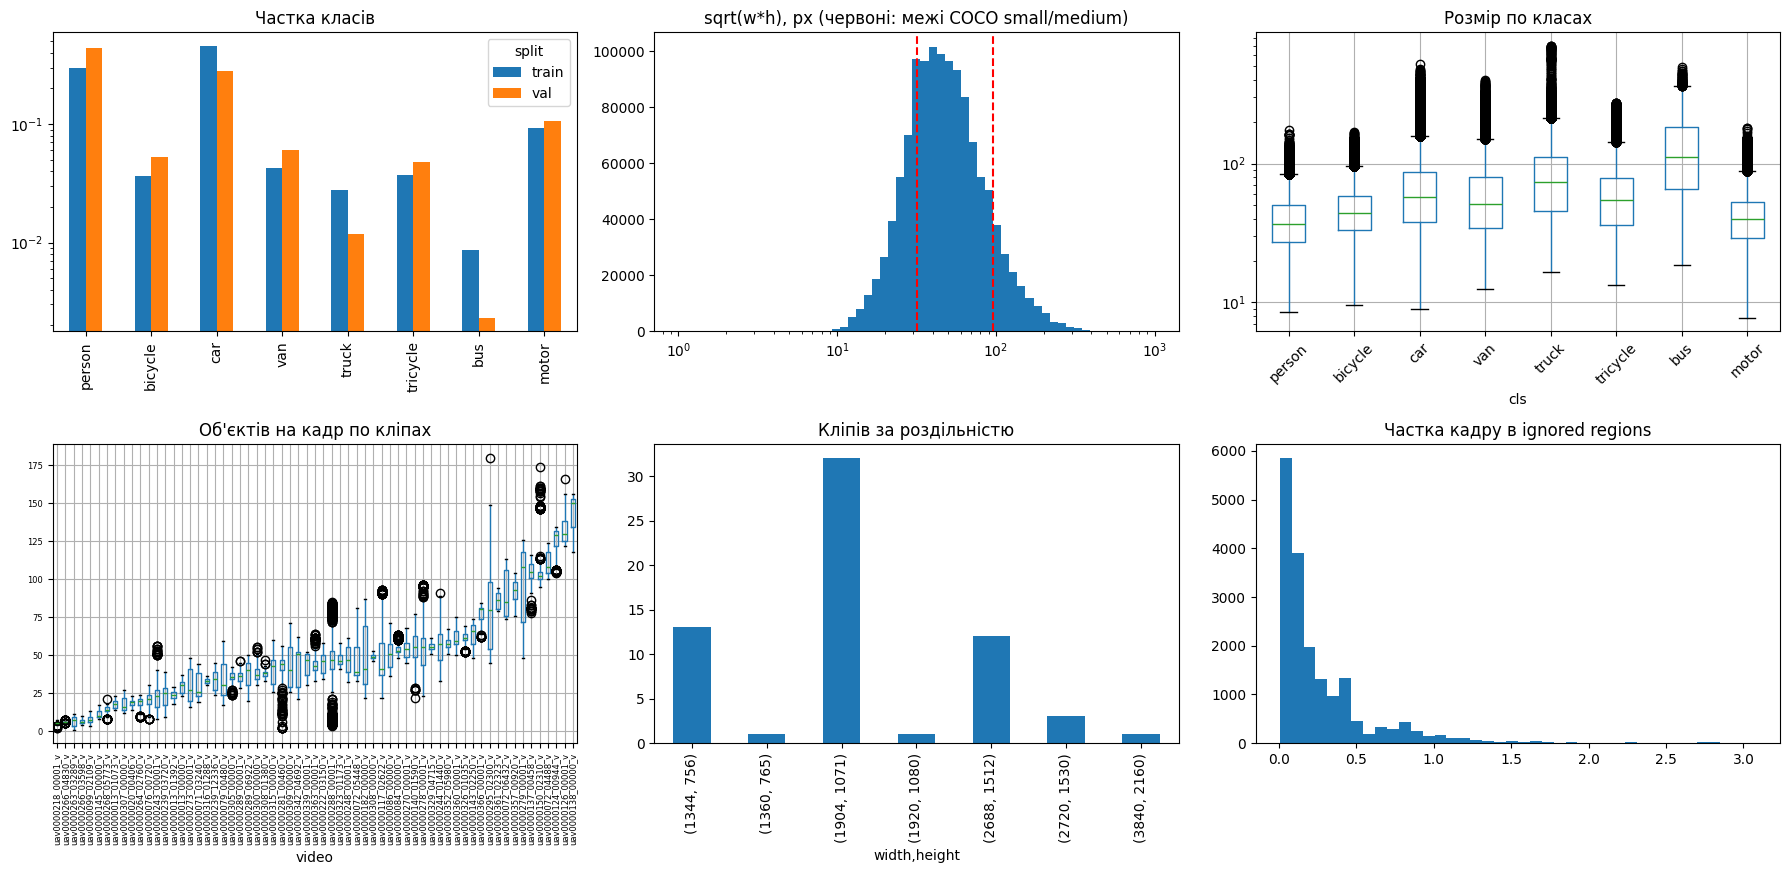

bucket  small  medium  large
split                       
train   0.249   0.635  0.116
val     0.192   0.695  0.113
медіана sqrt(area), px: 46.4 | медіана відн. розміру: 0.0318
об'єктів/кадр: mean 45.1, p95 111, max 180
кадрів з ignored regions: 67.5%


In [4]:
obj = pd.concat([obj_tr.assign(split='train'), obj_va.assign(split='val')])
obj['size'] = np.sqrt(obj.w * obj.h)                     # px
obj['rel']  = obj['size'] / np.sqrt(obj.width * obj.height)
obj['bucket'] = pd.cut(obj['size'], [0, 32, 96, 1e9], labels=['small','medium','large'])

fig, ax = plt.subplots(2, 3, figsize=(18, 9))

cc = obj.groupby(['split','cls']).size().unstack(0)
(cc / cc.sum()).set_axis(CLASSES).plot.bar(ax=ax[0,0], title='Частка класів'); ax[0,0].set_yscale('log')

ax[0,1].hist(obj['size'], bins=np.logspace(0, 3, 60)); ax[0,1].set_xscale('log')
for v in (32, 96): ax[0,1].axvline(v, c='r', ls='--')
ax[0,1].set_title('sqrt(w*h), px (червоні: межі COCO small/medium)')

obj.boxplot(column='size', by='cls', ax=ax[0,2]); ax[0,2].set_yscale('log')
ax[0,2].set_xticklabels(CLASSES, rotation=45); ax[0,2].set_title('Розмір по класах')

per_frame = obj.groupby(['split','video','frame_id']).size().rename('n').reset_index()
order = per_frame.groupby('video').n.mean().sort_values().index
per_frame['video'] = pd.Categorical(per_frame.video, order)
per_frame.boxplot(column='n', by='video', ax=ax[1,0], rot=90, fontsize=6); ax[1,0].set_title("Об'єктів на кадр по кліпах")

res = pd.concat([imgs_tr, imgs_va]).drop_duplicates('video')
res.groupby(['width','height']).size().plot.bar(ax=ax[1,1], title='Кліпів за роздільністю')

ign = pd.concat([ign_tr, ign_va])
ign_frac = (ign.w * ign.h / (ign.width * ign.height)).groupby(ign.image_id).sum()
ax[1,2].hist(ign_frac, bins=40); ax[1,2].set_title('Частка кадру в ignored regions')

plt.suptitle(''); plt.tight_layout(); plt.savefig(CACHE / 'eda.png', dpi=110); plt.show()

print(obj.groupby('split').bucket.value_counts(normalize=True).unstack().round(3))
print('медіана sqrt(area), px: %.1f | медіана відн. розміру: %.4f' % (obj['size'].median(), obj['rel'].median()))
print("об'єктів/кадр: mean %.1f, p95 %d, max %d" % (per_frame.n.mean(), per_frame.n.quantile(.95), per_frame.n.max()))
print('кадрів з ignored regions: %.1f%%' % (100 * ign.image_id.nunique() / (len(imgs_tr) + len(imgs_va))))

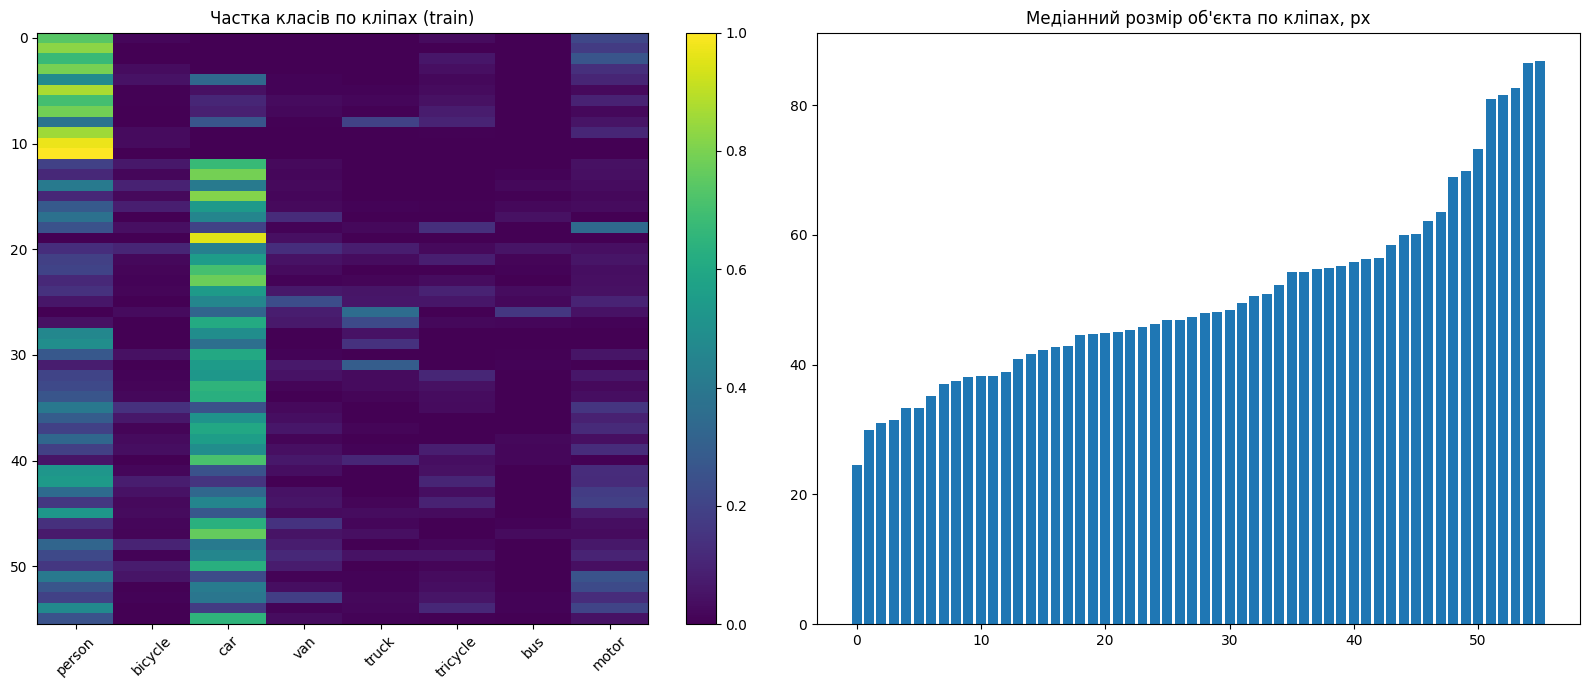

ignored regions за orig_category_id:
 orig_category_id
0     498952
11     11792
anchors (w,h) при imgsz=960:
 [[ 6.9 11.7]
 [14.9 12.1]
 [11.4 22.2]
 [23.9 17.6]
 [19.5 32.8]
 [40.  23.3]
 [36.1 48. ]
 [70.8 36.3]
 [92.8 75. ]]
співвідношення h/w (p10/p50/p90): [0.47 1.06 2.25]


In [5]:
from sklearn.cluster import KMeans
assert not set(imgs_tr.video) & set(imgs_va.video), 'кліпи train/val перетинаються!'

mix = pd.crosstab(obj_tr.video, obj_tr.cls, normalize='index'); mix.columns = CLASSES
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
im = ax[0].imshow(mix.values, aspect='auto'); ax[0].set_xticks(range(8)); ax[0].set_xticklabels(CLASSES, rotation=45)
ax[0].set_title('Частка класів по кліпах (train)'); plt.colorbar(im, ax=ax[0])
med = obj_tr.assign(s=np.sqrt(obj_tr.w*obj_tr.h)).groupby('video').s.median().sort_values()
ax[1].bar(range(len(med)), med.values); ax[1].set_title("Медіанний розмір об'єкта по кліпах, px")
plt.tight_layout(); plt.savefig(CACHE / 'per_clip.png', dpi=110); plt.show()

if 'orig_category_id' in ign_tr:
    print('ignored regions за orig_category_id:\n', ign_tr['orig_category_id'].value_counts().to_string())

sc = 960 / np.maximum(obj_tr.width, obj_tr.height)         # масштаб до imgsz=960
wh = np.c_[obj_tr.w * sc, obj_tr.h * sc]
km = KMeans(9, n_init=3, random_state=SEED).fit(np.log(wh))
A = np.exp(km.cluster_centers_); A = A[np.argsort(A[:,0]*A[:,1])]
np.save(CACHE / 'anchors960.npy', A)
print('anchors (w,h) при imgsz=960:\n', A.round(1))
print('співвідношення h/w (p10/p50/p90):', np.percentile(wh[:,1]/wh[:,0], [10, 50, 90]).round(2))

In [6]:
def track_iou(o, k):
    a = o[['video','track_id','frame_id','x','y','w','h']]
    b = a.assign(frame_id=a.frame_id - k)
    m = a.merge(b, on=['video','track_id','frame_id'], suffixes=('','_b'))
    ix = (np.minimum(m.x+m.w, m.x_b+m.w_b) - np.maximum(m.x, m.x_b)).clip(0)
    iy = (np.minimum(m.y+m.h, m.y_b+m.h_b) - np.maximum(m.y, m.y_b)).clip(0)
    inter = ix * iy
    return (inter / (m.w*m.h + m.w_b*m.h_b - inter)).median()

o = obj_tr[obj_tr.track_id >= 0]
for k in [1, 2, 3, 5, 10]:
    print(f"крок {k}: медіанний IoU того ж об'єкта = {track_iou(o, k):.3f}")

крок 1: медіанний IoU того ж об'єкта = 0.897
крок 2: медіанний IoU того ж об'єкта = 0.810
крок 3: медіанний IoU того ж об'єкта = 0.731
крок 5: медіанний IoU того ж об'єкта = 0.597
крок 10: медіанний IoU того ж об'єкта = 0.357


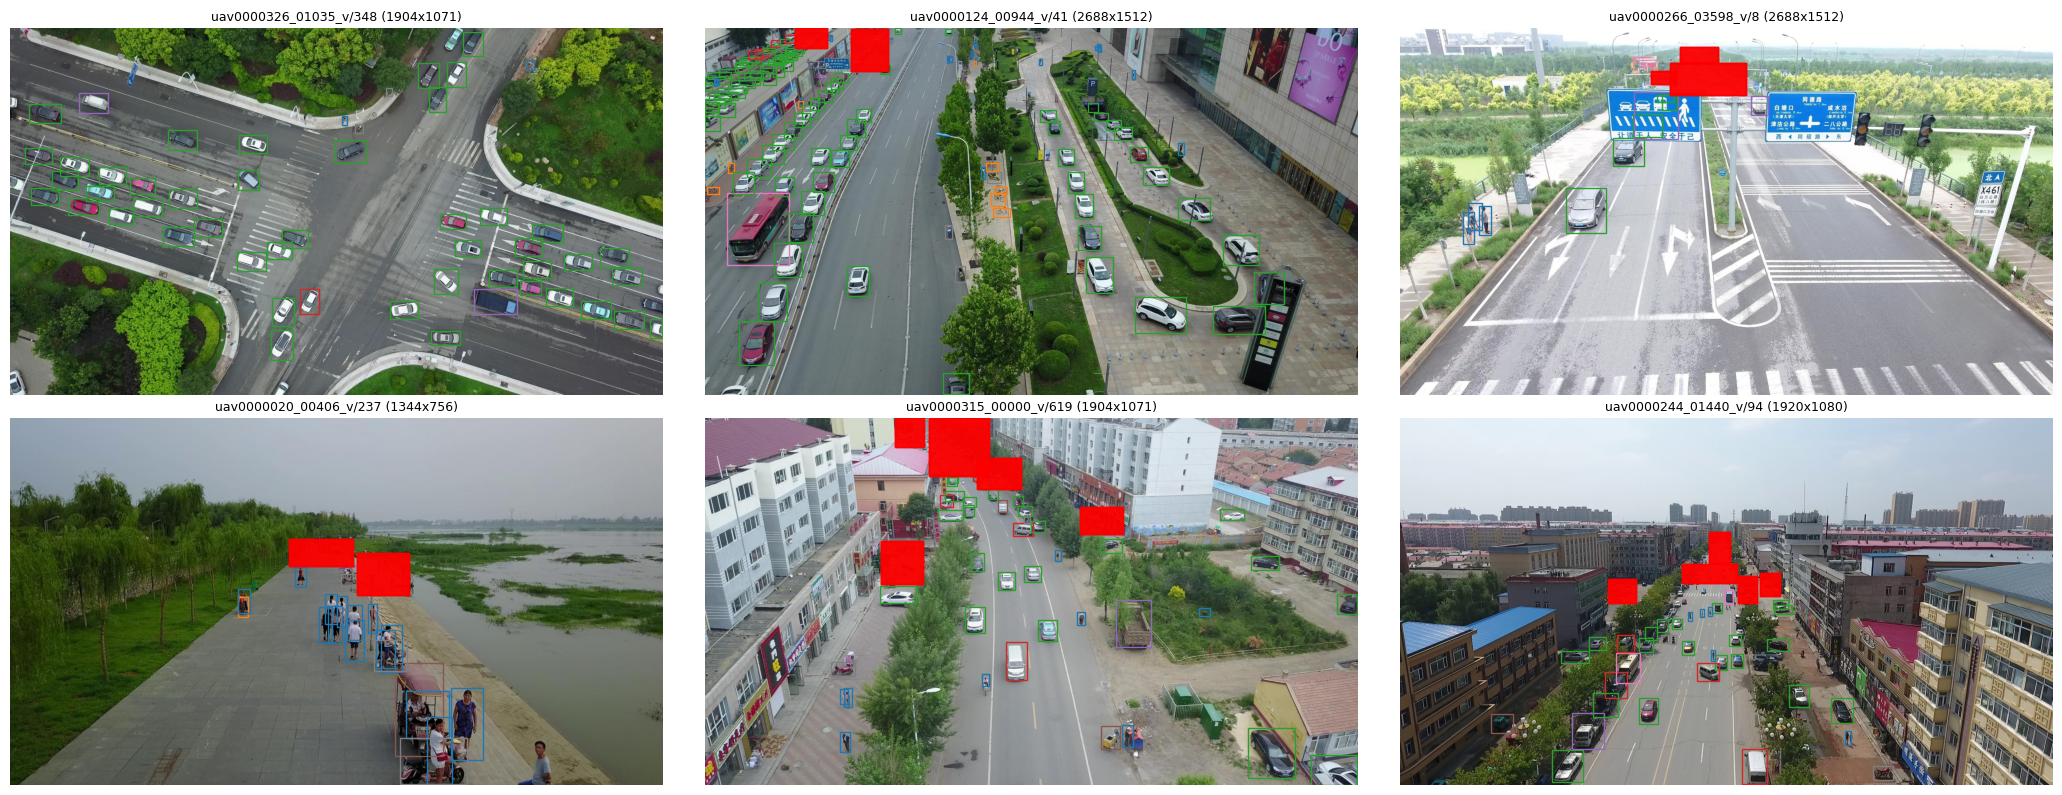

In [7]:
def show(split_imgs, obj_df, ign_df, n=6, seed=SEED):
    rng = np.random.RandomState(seed)
    sample = split_imgs.sample(n, random_state=rng)
    fig, axs = plt.subplots(2, n // 2, figsize=(7 * n // 2, 8))
    for ax_, (_, r) in zip(axs.ravel(), sample.iterrows()):
        ax_.imshow(Image.open(r.path)); ax_.axis('off')
        ax_.set_title(f'{r.video}/{r.frame_id} ({r.width}x{r.height})', fontsize=9)
        for _, b in obj_df[obj_df.image_id == r.image_id].iterrows():
            ax_.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=False, ec=plt.cm.tab10(int(b.cls)), lw=1))
        for _, b in ign_df[ign_df.image_id == r.image_id].iterrows():
            ax_.add_patch(patches.Rectangle((b.x, b.y), b.w, b.h, fill=True, fc='red', alpha=.3, ec='red'))
    plt.tight_layout(); plt.savefig(CACHE / 'gt_samples.png', dpi=100); plt.show()

show(imgs_tr, obj_tr, ign_tr)

### Preprocessing

In [22]:
s = imgs_tr.sort_values(['video','frame_id'])
sel = s[s.groupby('video').cumcount() % STEP == 0]          # кожен STEP-й кадр кліпу
ign_by_img = {k: g[['x','y','w','h']].values for k, g in ign_tr.groupby('image_id')}

def prep(r):
    out = WORK / 'train' / 'images' / r.video / Path(r.path).name
    if out.exists(): return
    out.parent.mkdir(parents=True, exist_ok=True)
    im = Image.open(r.path).convert('RGB')
    if MASK_IGNORE:
        a = np.array(im)
        for x, y, w, h in ign_by_img.get(r.image_id, []):
            a[int(y):int(np.ceil(y+h)), int(x):int(np.ceil(x+w))] = 114
        im = Image.fromarray(a)
    im.save(out, quality=95)
    lbl = DATA/'train'/'labels'/r.video/(Path(r.path).stem + '.txt')
    dst = WORK/'train'/'labels'/r.video/lbl.name
    dst.parent.mkdir(parents=True, exist_ok=True)
    if lbl.exists(): shutil.copy(lbl, dst)

with ThreadPoolExecutor(8) as ex:
    list(ex.map(prep, [r for _, r in sel.iterrows()]))

yaml = f"""path: /content
train: {WORK}/train/images
val: {DATA}/val/images
names: {dict(enumerate(CLASSES))}
"""
(WORK / 'data_yolo.yaml').write_text(yaml)
shutil.copy(WORK / 'data_yolo.yaml', CACHE / 'data_yolo.yaml')
print('train кадрів:', len(sel), '| val кадрів:', len(imgs_va))

train кадрів: 12114 | val кадрів: 2846


In [ ]:
!find /content/work/train/images -name "*.jpg" | wc -l
!find /content/work/train/labels -name "*.txt" | wc -l

## 4. Спільні функції: оцінка (COCO) і формування submission

In [23]:
!pip -q install ultralytics pycocotools
import time, contextlib, io
from ultralytics import YOLO, settings
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

settings.update({'wandb': False})   # поки не налаштований W&B
RES  = ROOT / 'results';     RES.mkdir(exist_ok=True)
RUNS = ROOT / 'ckpt';        RUNS.mkdir(exist_ok=True)
SUBS = ROOT / 'submissions'; SUBS.mkdir(exist_ok=True)

def predict_all(model, paths, imgsz, conf=0.001, iou=0.6):
    """-> ({шлях: (xyxy, score, cls)}, мс на кадр)"""
    out, t = {}, 0.
    for r in model.predict(paths, imgsz=imgsz, conf=conf, iou=iou, max_det=500,
                           half=True, stream=True, verbose=False, batch=16):
        b = r.boxes
        out[str(Path(r.path))] = (b.xyxy.cpu().numpy(), b.conf.cpu().numpy(),
                                  b.cls.cpu().numpy().astype(int))
        t += sum(r.speed.values())
    return out, t / max(len(paths), 1)

def drop_in_ignore(xyxy, sc, cl, ign, thr=0.5):
    """Відкинути детекції, що >=thr площі лежать в ignored regions."""
    if len(xyxy) == 0 or len(ign) == 0: return xyxy, sc, cl
    gx1, gy1, gx2, gy2 = ign[:,0], ign[:,1], ign[:,0]+ign[:,2], ign[:,1]+ign[:,3]
    ix = (np.minimum(xyxy[:,None,2], gx2) - np.maximum(xyxy[:,None,0], gx1)).clip(0)
    iy = (np.minimum(xyxy[:,None,3], gy2) - np.maximum(xyxy[:,None,1], gy1)).clip(0)
    area = ((xyxy[:,2]-xyxy[:,0]) * (xyxy[:,3]-xyxy[:,1])).clip(1e-6)
    keep = (ix * iy).sum(1) / area < thr
    return xyxy[keep], sc[keep], cl[keep]

def evaluate(model, imgsz, n=None):
    """COCO mAP / AP50 / AP_small / AP_medium / AP_large на val. n: підвибірка для швидкого тесту."""
    v = imgs_va if n is None else imgs_va.sample(n, random_state=SEED)
    preds, ms = predict_all(model, [str(p) for p in v.path], imgsz)
    ign = {k: g[['x','y','w','h']].values for k, g in ign_va.groupby('image_id')}
    dets = []
    for iid, p in zip(v.image_id, v.path):
        xyxy, sc, cl = preds[str(Path(p))]
        xyxy, sc, cl = drop_in_ignore(xyxy, sc, cl, ign.get(iid, np.zeros((0, 4))))
        for (x1, y1, x2, y2), s, c in zip(xyxy, sc, cl):
            dets.append({'image_id': int(iid), 'category_id': int(c)+1,
                         'bbox': [float(x1), float(y1), float(x2-x1), float(y2-y1)],
                         'score': float(s)})
    gt = json.load(open(DATA/'val'/'annotations_coco.json'))
    gt['annotations'] = [a for a in gt['annotations'] if not a.get('iscrowd', 0)]
    for a in gt['annotations']: a.setdefault('area', a['bbox'][2] * a['bbox'][3])
    with contextlib.redirect_stdout(io.StringIO()):
        cg = COCO(); cg.dataset = gt; cg.createIndex()
        cd = cg.loadRes(dets)
        E = COCOeval(cg, cd, 'bbox'); E.params.imgIds = [int(i) for i in v.image_id]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    return dict(mAP=s[0], AP50=s[1], AP_small=s[3], AP_medium=s[4], AP_large=s[5], ms_per_img=ms)

def make_submission(model, imgsz, out_csv):
    test = pd.read_csv(DATA / 'test_images.csv')
    preds, _ = predict_all(model, [str(DATA/f) for f in test.file_name], imgsz)
    rows = []
    for iid, f in zip(test.image_id, test.file_name):
        xyxy, sc, cl = preds[str(DATA/f)]
        rows.append((iid, ' '.join(f'{c} {p:.4f} {x1:.1f} {y1:.1f} {x2-x1:.1f} {y2-y1:.1f}'
                                   for (x1, y1, x2, y2), p, c in zip(xyxy, sc, cl))))
    pd.DataFrame(rows, columns=['image_id', 'PredictionString']).to_csv(out_csv, index=False)
    print('збережено', out_csv, '| рядків:', len(rows))

## 9. [A] YOLO baseline (anchor-free): тренування → оцінка → сабмішен

In [ ]:
SMOKE = False
IMGSZ, EPOCHS, BATCH, CLOSE_MOSAIC = 960, 12, 16, 3
EXP = f'A_yolo11s_img{IMGSZ}_e{EPOCHS}_cm{CLOSE_MOSAIC}'
last = RUNS / EXP / 'weights' / 'last.pt'
best = RUNS / EXP / 'weights' / 'best.pt'

if (RES / f'{EXP}.json').exists():
    print('Вже зроблено, пропускаю:', EXP)
else:
    if last.exists():                                  # відновлення після обриву
        try:
            YOLO(str(last)).train(resume=True)
        except Exception as e:
            print('resume пропущено:', e)
    else:
        YOLO('yolo11s.pt').train(
            data=str(WORK/'data_yolo.yaml'), imgsz=IMGSZ, batch=BATCH, seed=SEED,
            epochs=1 if SMOKE else EPOCHS, fraction=0.02 if SMOKE else 1.0,
            project=str(RUNS), name=EXP, exist_ok=True,
            amp=True, workers=2, plots=True, patience=100,
            close_mosaic=CLOSE_MOSAIC)

    m = YOLO(str(best))
    metrics = evaluate(m, IMGSZ, n=100 if SMOKE else None)
    print({k: round(float(v), 4) for k, v in metrics.items()})

    cfg = dict(model='yolo11s', imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, step=STEP,
               mask_ignore=MASK_IGNORE, seed=SEED, smoke=SMOKE,
               close_mosaic=CLOSE_MOSAIC, optimizer='auto(AdamW)')
    json.dump({'metrics': {k: float(v) for k, v in metrics.items()}, 'cfg': cfg},
              open(RES / f'{EXP}.json', 'w'), indent=2)
    make_submission(m, IMGSZ, SUBS / f'{EXP}.csv')

New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/data_yolo.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.

In [26]:
import torch

def predict_all(model, paths, imgsz, conf=0.001, iou=0.6):
    out, t = {}, 0.
    for r in model.predict(paths, imgsz=imgsz, conf=conf, iou=iou, max_det=500,
                           half=torch.cuda.is_available(), stream=True,
                           verbose=False, batch=8):
        b = r.boxes
        out[str(Path(r.path))] = (b.xyxy.cpu().numpy(), b.conf.cpu().numpy(),
                                  b.cls.cpu().numpy().astype(int))
        t += sum(r.speed.values())
    return out, t / max(len(paths), 1)

def fmt(xyxy, sc, cl):
    return ' '.join(f'{c} {p:.4f} {x1:.1f} {y1:.1f} {x2-x1:.1f} {y2-y1:.1f}'
                    for (x1, y1, x2, y2), p, c in zip(xyxy, sc, cl))

def make_submission(model, imgsz, out_csv, limit=None):
    test = pd.read_csv(DATA / 'test_images.csv')
    if limit: test = test.head(limit)
    part = Path(str(out_csv) + '.part')
    done = {}
    if part.exists():
        done = dict(pd.read_csv(part, dtype=str, keep_default_na=False).values)
        print('вже готово зображень:', len(done))
    todo = test[~test.image_id.isin(done)]
    n_clips = todo['clip'].nunique()
    for i, (clip, g) in enumerate(todo.groupby('clip')):
        preds, _ = predict_all(model, [str(DATA/f) for f in g.file_name], imgsz)
        for iid, f in zip(g.image_id, g.file_name):
            done[iid] = fmt(*preds[str(DATA/f)])
        pd.DataFrame(list(done.items()), columns=['image_id', 'PredictionString']).to_csv(part, index=False)
        print(f'кліп {clip} ({i+1}/{n_clips}), всього {len(done)}/{len(test)}')
    out = pd.DataFrame({'image_id': test.image_id, 'PredictionString': [done[i] for i in test.image_id]})
    out.to_csv(out_csv, index=False)
    print('збережено', out_csv, '| рядків:', len(out))

In [27]:
import time
EXP = 'A_yolo11s_img960_e12_cm3'
m = YOLO(str(RUNS / EXP / 'weights' / 'best.pt'))
t0 = time.time()
make_submission(m, 960, SUBS / 'test20.csv', limit=20)
dt = time.time() - t0
print(f'{dt:.1f} с на 20 кадрів → повний тест ≈ {dt/20*3811/60:.0f} хв')
s = pd.read_csv(SUBS / 'test20.csv'); print(s.shape); print(s.PredictionString.iloc[0][:150])

вже готово зображень: 20
збережено /content/drive/MyDrive/project/submissions/test20.csv | рядків: 20
0.1 с на 20 кадрів → повний тест ≈ 0 хв
(20, 2)
0 0.7762 1242.5 775.8 46.7 118.2 0 0.7608 1709.9 789.4 60.3 152.4 0 0.7422 1190.1 622.5 28.6 74.4 0 0.7358 1653.2 789.6 64.4 149.2 0 0.7265 974.2 716.


In [28]:
make_submission(m, 960, SUBS / f'{EXP}.csv')

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_001 (1/48), всього 36/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_002 (2/48), всього 96/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_003 (3/48), всього 229/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_004 (4/48), всього 302/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_005 (5/48), всього 382/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_006 (6/48), всього 524/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп clip_007 (7/48), всього 591/3811
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
кліп cli

In [29]:
s = pd.read_csv(SUBS / 'A_yolo11s_img960_e12_cm3.csv', keep_default_na=False)
t = pd.read_csv(DATA / 'test_images.csv')
print(s.shape, '| id збігаються з test_images:', list(s.image_id) == list(t.image_id))
print('порожніх рядків:', (s.PredictionString == '').sum())
n = s.PredictionString.str.split().str.len() // 6
print('детекцій на кадр: mean %.0f, max %d' % (n.mean(), n.max()))
print(s.PredictionString.iloc[0][:120])

(3811, 2) | id збігаються з test_images: True
порожніх рядків: 0
детекцій на кадр: mean 394, max 500
0 0.7762 1242.5 775.8 46.7 118.2 0 0.7608 1709.9 789.4 60.3 152.4 0 0.7422 1190.1 622.5 28.6 74.4 0 0.7358 1653.2 789.6 
